Dataset Shape: (1470, 35)

First 5 Rows:
   Age Attrition     BusinessTravel  DailyRate              Department  \
0   41       Yes      Travel_Rarely       1102                   Sales   
1   49        No  Travel_Frequently        279  Research & Development   
2   37       Yes      Travel_Rarely       1373  Research & Development   
3   33        No  Travel_Frequently       1392  Research & Development   
4   27        No      Travel_Rarely        591  Research & Development   

   DistanceFromHome  Education EducationField  EmployeeCount  EmployeeNumber  \
0                 1          2  Life Sciences              1               1   
1                 8          1  Life Sciences              1               2   
2                 2          2          Other              1               4   
3                 3          4  Life Sciences              1               5   
4                 2          1        Medical              1               7   

   ...  RelationshipSatisfaction 

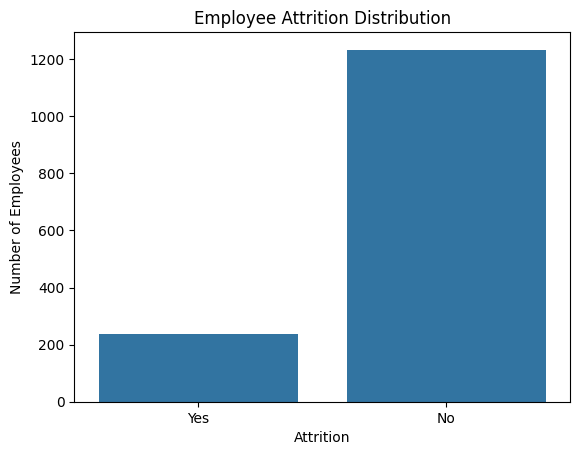


Features after Encoding: (1470, 47)
Training Data: (1176, 47)
Testing Data: (294, 47)

MODEL COMPARISON
                 Model  Accuracy  Precision  Recall  F1 Score
0  Logistic Regression     0.861      0.615   0.340     0.438
1        Decision Tree     0.833      0.450   0.191     0.269
2        Random Forest     0.830      0.364   0.085     0.138

Random Forest Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.97      0.91       247
           1       0.36      0.09      0.14        47

    accuracy                           0.83       294
   macro avg       0.61      0.53      0.52       294
weighted avg       0.77      0.83      0.78       294



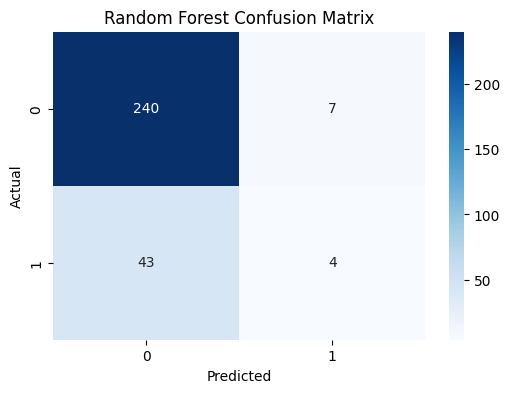

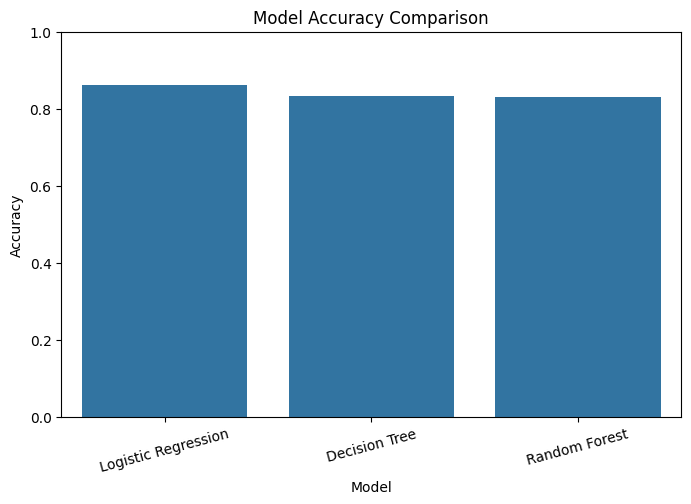

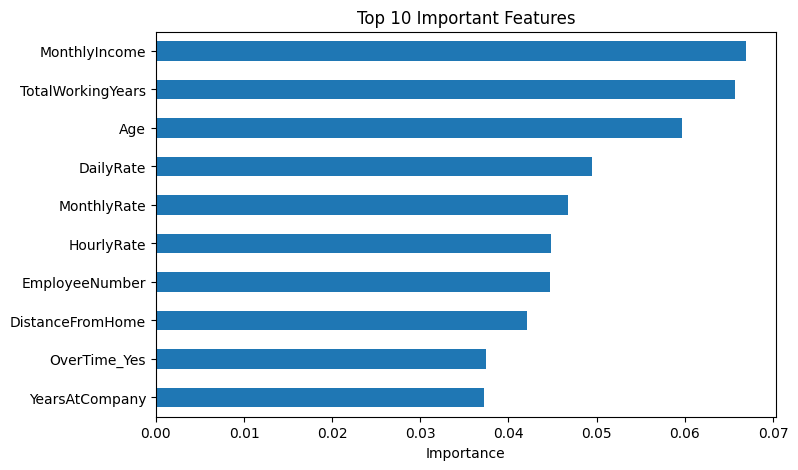

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report )



#  LOAD DATASET

df = pd.read_csv("hr.csv.csv")

print("Dataset Shape:", df.shape)
print("\nFirst 5 Rows:")
print(df.head())

print("\nMissing Values:")
print(df.isnull().sum().sum())

# Em[ployee graph say how many saty and how many leAve 

sns.countplot(x="Attrition", data=df)

plt.title("Employee Attrition Distribution")
plt.xlabel("Attrition")
plt.ylabel("Number of Employees")
plt.show()



df["Attrition"] = df["Attrition"].map({
    "Yes": 1,
    "No": 0
})


# X = employee information
# y = target 

X = df.drop("Attrition", axis=1)
y = df["Attrition"]


# Categorical columns  to numerical columns 

X = pd.get_dummies(X, drop_first=True)

print("\nFeatures after Encoding:", X.shape)


# TRAIN TEST SPLIT

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)


# FEATURE 

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


 # LOGISTIC REGRESSION

log_model = LogisticRegression(max_iter=1000)

log_model.fit(X_train_scaled, y_train)

log_pred = log_model.predict(X_test_scaled)


# DECISION TREE

dt_model = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

dt_model.fit(X_train, y_train)

dt_pred = dt_model.predict(X_test)


 # RANDOM FOREST

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)


# MODEL COMPARISON

results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],

    "Accuracy": [
        accuracy_score(y_test, log_pred),
        accuracy_score(y_test, dt_pred),
        accuracy_score(y_test, rf_pred)
    ],

    "Precision": [
        precision_score(y_test, log_pred),
        precision_score(y_test, dt_pred),
        precision_score(y_test, rf_pred)
    ],

    "Recall": [
        recall_score(y_test, log_pred),
        recall_score(y_test, dt_pred),
        recall_score(y_test, rf_pred)
    ],

    "F1 Score": [
        f1_score(y_test, log_pred),
        f1_score(y_test, dt_pred),
        f1_score(y_test, rf_pred)
    ]
})

print("\nMODEL COMPARISON")
print(results.round(3))


print("\nRandom Forest Classification Report:")
print(classification_report(y_test, rf_pred))


# 11. CONFUSION MATRIX

cm = confusion_matrix(y_test, rf_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


# MODEL ACCURACY COMPARISON

plt.figure(figsize=(8, 5))

sns.barplot(
    x="Model",
    y="Accuracy",
    data=results
)

plt.ylim(0, 1)
plt.title("Model Accuracy Comparison")
plt.xticks(rotation=15)
plt.show()


# FEATURE IMPORTANCE

importance = pd.Series(
    rf_model.feature_importances_,
    index=X.columns
)

importance = importance.sort_values(
    ascending=False
).head(10)


# Top 10 important features ka graph

plt.figure(figsize=(8, 5))

importance.sort_values().plot(
    kind="barh"
)

plt.title("Top 10 Important Features")
plt.xlabel("Importance")
plt.show()


